# Numerical PDEs

## Table of Contents

- [Topic 1: Discretizing Black-Scholes on Non-Uniform Spatial Grids](#topic-1-discretizing-black-scholes-on-non-uniform-spatial-grids)
  - [Part 1: Why Non-Uniform Grids & The Coordinate Transformation](#part-1-why-non-uniform-grids--the-coordinate-transformation)
  - [Part 2: Finite Differences on an Uneven Grid & Matrix Assembly](#part-2-finite-differences-on-an-uneven-grid--matrix-assembly)
- [Topic 2: The Linear Complementarity Problem (LCP)](#topic-2-the-linear-complementarity-problem-lcp)
  - [Part 1: Economic Intuition & Free Boundary Mechanics](#part-1-economic-intuition--free-boundary-mechanics)
  - [Part 2: Continuous & Discrete LCP Formulation](#part-2-continuous--discrete-lcp-formulation)
- [Topic 3: PSOR vs. Penalty Method](#topic-3-psor-vs-penalty-method)
  - [Part 1: Projected Successive Over-Relaxation (PSOR)](#part-1-projected-successive-over-relaxation-psor)
  - [Part 2: The Penalty Method & Vectorized Newton Iteration (GPU-Ready)](#part-2-the-penalty-method--vectorized-newton-iteration-gpu-ready)

## Topic 1: Discretizing Black-Scholes on non-uniform Spatial Grids

### Part 1: Why Non-Uniform Grids & The Coordinate Transformation

To solve a PDE numerically, we turn continuous space ($S$) and time ($t$) into a discrete grid of points.

#### 1. Why Non-Uniform Grids?
In the Black-Scholes PDE, the domain for the stock price is $S \in [0, \infty)$. Practically, we truncate this at some large upper boundary $S_{\max}$ (e.g., $S_{\max} = 4K$ or $5K$).

If we use a **uniform grid** ($S_i = i \cdot \Delta S$):
* **Wasted resolution:** Most of the interesting financial action, the payoff kink at $S=K$, high Gamma ($\frac{\partial^2 V}{\partial S^2}$), and the early-exercise boundary $S^*(t)$, happens in a relatively narrow region around the strike price $K$.
* **Computational cost:** To get high accuracy near $K$ on a uniform grid, you need a tiny $\Delta S$, which forces you to create thousands of unnecessary grid points at values of $S$ far from $K$ where the option price is just a flat line ($V \approx 0$ for a put). Because we will eventually batch many options on a GPU, keeping the spatial grid small ($N \approx 100\text{–}200$ points) is critical for speed.

The natural and obvious solution is to use non-uniform grid, something like densely clustered grid points around $S = K$, and stretch them out smoothly as $S \to 0$ and $S \to S_{\max}$.

#### 2. How to Construct a Non-Uniform Grid (The Coordinate Transformation)
Instead of spacing $S$ unevenly by hand, standard quantitative finance practice uses a smooth, invertible coordinate transformation from a **uniform computational variable $\xi \in [0, 1]$** to the **non-uniform physical stock price $S(\xi)$**. The standard mapping for options (Tavella & Randall) uses the hyperbolic sine function:

$$S(\xi) = K + c \sinh\left( \xi \cdot c_2 + (1 - \xi) \cdot c_1 \right)$$

where
* $\xi_i = \frac{i}{N}$ for $i = 0, 1, \dots, N$ is a completely uniform grid.
* $c > 0$ is a **concentration parameter** (smaller $c$ packs more points tightly around $K$; typically $c \approx K/5$ or $K/10$) (in the next plot, notice the curves turning point is at height $K$).
* $c_1$ and $c_2$ are constants pinned down by the boundary conditions $S(0) = 0$ and $S(1) = S_{\max}$:
  $$c_1 = \operatorname{arcsinh}\left(-\frac{K}{c}\right), \qquad c_2 = \operatorname{arcsinh}\left(\frac{S_{\max} - K}{c}\right)$$

Notice the behavior of $\sinh(x)$: near $x = 0$ (which corresponds to $S = K$), the derivative $\cosh(0) = 1$ is at its minimum, meaning $\Delta S_i = S_{i+1} - S_i$ is smallest right at the strike $K$. Far away from $K$, $\cosh(x)$ grows exponentially, stretching the grid. Note in our diagram (with $S=100,\,K=20,\,c=3$), the interval $[0.6, 1]$ is mapped to $[0, 20]$ whereas the other part $[0, 0.6]$ is mapped to $[20, 100]$. The slope is at its lowest (most negative) at $\xi=0$ (when $K=S_{\text{max}}$).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

#sliders
k_slider = widgets.FloatSlider(value=20.0, min=0.0, max=100.0, step=1, description='K:', continuous_update=True)
s_slider = widgets.FloatSlider(value=100.0, min=0.0, max=200.0, step=1, description='S:', continuous_update=True)
c_slider = widgets.FloatSlider(value=3.0, min=0, max=100.0, step=1, description='c:', continuous_update=True)

#container
out = widgets.Output()

def update_plot(change=None):
    K = k_slider.value
    S = s_slider.value
    c = c_slider.value
    
    x = np.linspace(0.0, 1.0, 500)
    y = K + c * np.sinh(x * np.arcsinh(-K / c) + (1 - x) * np.arcsinh((S - K) / c))
    
    with out:
        clear_output(wait=True)  # Smoothly replaces the old plot
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.plot(x, y, label=f'K={K:.1f}, S={S:.1f}, c={c:.2f}', color="green", linewidth=1.5)
        ax.scatter([0, 1], [S, 0], 
                   color="red", 
                   zorder=5, label='Endpoints: (0, S) and (1, 0)')
        
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
        ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
        ax.axhline(K, color='blue', linewidth=0.5, linestyle='--')
        
        ax.set_title(rf"$f(\xi) = {K} + {c} \sinh\left(\xi \mathrm{{arcsinh}}\left(-\frac{{{K}}}{{{c}}}\right) + (1-\xi) \mathrm{{arcsinh}}\left(\frac{{{S}-{K}}}{{{c}}}\right)\right)$", 
                     fontsize=11, pad=12)
        ax.set_xlabel(rf"$\xi$")
        ax.set_ylabel(rf"$S(\xi)$")
        ax.grid(True, alpha=0.3)
        ax.legend()
        plt.tight_layout()
        plt.show()

# Link sliders to the update function
k_slider.observe(update_plot, names='value')
s_slider.observe(update_plot, names='value')
c_slider.observe(update_plot, names='value')

# Display UI and show first draw
ui = widgets.VBox([k_slider, s_slider, c_slider, out])
display(ui)
update_plot()

We can update the code very easily by adding uniform ticks in the $\xi$ axis and showing where their images land showcasing the non-uniform grid we have created, specially highlighting how the grid is dense near $K$. We will also take some design liberty to add lines joining the inputs $\{\xi_1, \cdots, \xi_N\}$ with their images $\{S_0, \cdots, S_N\}$ using `ax.axhline` and `ax.axvline`.

In [2]:
k_slider = widgets.FloatSlider(value=20.0, min=0.0, max=100.0, step=1, description='K:', continuous_update=True)
s_slider = widgets.FloatSlider(value=100.0, min=0.0, max=200.0, step=1, description='S:', continuous_update=True)
c_slider = widgets.FloatSlider(value=3.0, min=0.0, max=100.0, step=1, description='c:', continuous_update=True)
n_slider = widgets.IntSlider(value=15, min=3, max=50, step=1, description='Grid N:', continuous_update=True)

out = widgets.Output()

def f_map(xi, K, S, c):
    return K + c * np.sinh(xi * np.arcsinh(-K / c) + (1 - xi) * np.arcsinh((S - K) / c))

def update_plot(change=None):
    K = k_slider.value
    S = s_slider.value
    c = c_slider.value
    N = n_slider.value
    
    x = np.linspace(0.0, 1.0, 500)
    y = f_map(x, K, S, c)
    
    # Uniform grid in xi and non-uniform image in S(xi)
    xi_ticks = np.linspace(0.0, 1.0, N)
    S_ticks = f_map(xi_ticks, K, S, c)
    
    with out:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.plot(x, y, label=f'K={K:.1f}, S={S:.1f}, c={c:.2f}', color="green", linewidth=1.5)
        
        # Projection lines mapping uniform xi -> curve -> non-uniform S(xi)
        for xi_val, S_val in zip(xi_ticks, S_ticks):
            ax.plot([xi_val, xi_val], [0, S_val], color='gray', linestyle=':', linewidth=0.6, alpha=0.5)
            ax.plot([0, xi_val], [S_val, S_val], color='gray', linestyle=':', linewidth=0.6, alpha=0.5)
        
        # Uniform black ticks on x and non uniform ones on y (the main point of this recode)
        ax.scatter(xi_ticks, np.zeros_like(xi_ticks), color='black', marker='|', s=80, linewidths=1.5, zorder=6, label=rf'Uniform $\xi$ grid ($N={N}$)')
        ax.scatter(np.zeros_like(S_ticks), S_ticks, color='green', marker='_', s=80, linewidths=1.5, zorder=6, label=rf'Non-uniform $S(\xi)$ image')

        ax.scatter([0, 1], [S, 0], color="red", zorder=7, s=25, label='Endpoints: (0, S) and (1, 0)')
        ax.axhline(0, color='black', linewidth=0.8)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.axhline(K, color='blue', linewidth=0.7, linestyle='--', label=f'Concentration K={K:.1f}')
        
        ax.set_title(rf"$S(\xi) = {K} + {c} \sinh\left(\xi \mathrm{{arcsinh}}\left(-\frac{{{K}}}{{{c}}}\right) + (1-\xi) \mathrm{{arcsinh}}\left(\frac{{{S}-{K}}}{{{c}}}\right)\right)$", 
                     fontsize=11, pad=12)
        ax.set_xlabel(rf"$\xi$")
        ax.set_ylabel(rf"$S(\xi)$")
        ax.grid(True, alpha=0.25)
        ax.legend(loc='upper right', fontsize=8.5)
        plt.tight_layout()
        plt.show()

for slider in (k_slider, s_slider, c_slider, n_slider):
    slider.observe(update_plot, names='value')

# Display UI and show first draw
ui = widgets.VBox([k_slider, s_slider, c_slider, n_slider, out])
display(ui)
update_plot()

### Part 2: Finite Differences on the transformed Grid

Now that we have a non-uniform grid $S_0, S_1, \dots, S_N$ clustered around the strike $K$, let's turn the continuous Black-Scholes PDE into a linear algebra problem that we can solve in NumPy. 

#### 1. The Backward Black-Scholes PDE
To make time move forward in our code, we rewrite the PDE in terms of **time to maturity** $\tau = T - t$ (so $\tau = 0$ is expiration, and $\tau = T$ is today):

$$\frac{\partial V}{\partial \tau} = \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + (r - q) S \frac{\partial V}{\partial S} - r V$$

*(where $q$ is the continuous dividend yield; set $q=0$ if none).* This is the standard transformation we do while solving for it using Heat kernal (we call it backward diffusion).

#### 2. Derivatives on an Uneven Grid
Assuming introductory numerical analysis is known, because we are going to use discrete differentiation, we continue with this topic. On a uniform grid, $\frac{\partial V}{\partial S} \approx \frac{V_{i+1} - V_{i-1}}{2\Delta S}$ (center difference form). On a **non-uniform grid**, the step to the left and the step to the right are different:
$$h_{i-1} = S_i - S_{i-1}, \qquad h_i = S_{i+1} - S_i$$

If you use standard centered differences without adjusting for $h_{i-1} \neq h_i$, your accuracy drops from second-order $O(h^2)$ to first-order $O(h)$! Instead, we do a Taylor expansion around $S_i$ to get the exact second-order accurate uneven finite-difference weights (as you know we pretty much do nothing but Taylor Expansion in numerical analysis). To preserve $O(h^2)$ accuracy, we want a linear combination of the three neighboring points:$$w_{-1} V_{i-1} + w_0 V_i + w_{+1} V_{i+1}$$where the weights $(w_{-1}, w_0, w_{+1})$ are chosen to match the exact derivative while eliminating lower-order error terms. 
Expand $V_{i-1} = V(S_i - h_{i-1})$ and $V_{i+1} = V(S_i + h_i)$ around $S_i$:$$V_{i-1} = V_i - h_{i-1} V'_i + \frac{1}{2} h_{i-1}^2 V''_i - \frac{1}{6} h_{i-1}^3 V'''_i + \dots$$$$V_{i+1} = V_i + h_i V'_i + \frac{1}{2} h_i^2 V''_i + \frac{1}{6} h_i^3 V'''_i + \dots$$Multiply the two equations by $w_{-1}$ and $w_{+1}$ and add $w_0 V_i$:$$w_{-1} V_{i-1} + w_0 V_i + w_{+1} V_{i+1} = (w_{-1} + w_0 + w_{+1}) V_i + (-h_{i-1} w_{-1} + h_i w_{+1}) V'_i + \frac{1}{2}(h_{i-1}^2 w_{-1} + h_i^2 w_{+1}) V''_i + O(h^3)$$This gives a $3 \times 3$ linear system to solve for the weights. 

* **First Derivative ($\frac{\partial V}{\partial S}$ at $S_i$):** We want the coefficient of $V_i$ to be $0$, the coefficient of $V'_i$ to be $1$, and the coefficient of $V''_i$ to be $0$:
$$w_{-1} + w_0 + w_{+1} = 0$$
$$-h_{i-1} w_{-1} + h_i w_{+1} = 1$$
$$h_{i-1}^2 w_{-1} + h_i^2 w_{+1} = 0$$
$$\frac{\partial V}{\partial S}(S_i) \approx -\frac{h_i}{h_{i-1}(h_{i-1} + h_i)} V_{i-1} + \frac{h_i - h_{i-1}}{h_{i-1} h_i} V_i + \frac{h_{i-1}}{h_i(h_{i-1} + h_i)} V_{i+1}$$

* **Second Derivative ($\frac{\partial^2 V}{\partial S^2}$ at $S_i$):**
  $$\frac{\partial^2 V}{\partial S^2}(S_i) \approx \frac{2}{h_{i-1}(h_{i-1} + h_i)} V_{i-1} - \frac{2}{h_{i-1} h_i} V_i + \frac{2}{h_i(h_{i-1} + h_i)} V_{i+1}$$

*Quick check: if you plug in $h_{i-1} = h_i = h$, these immediately collapse back into the familiar uniform formulas $\frac{V_{i+1} - V_{i-1}}{2h}$ and $\frac{V_{i-1} - 2V_i + V_{i+1}}{h^2}$!*

You can rewrite the second-derivative formula as a difference of slopes divided by the average cell width:$$\frac{\partial^2 V}{\partial S^2}(S_i) \approx \frac{\overbrace{\frac{V_{i+1} - V_i}{h_i}}^{\text{right slope}} - \overbrace{\frac{V_i - V_{i-1}}{h_{i-1}}}^{\text{left slope}}}{\frac{1}{2}(h_{i-1} + h_i)}$$Expanding that fraction gives the exact three-point weights above. This measures how fast the slope changes.

#### 3. Assembling the Spatial Operator Matrix $L$
When you substitute those two approximations into the right-hand side of the PDE at every interior grid point $i = 1, \dots, N-1$, the entire spatial differential operator becomes a **tridiagonal matrix** $L$:

$$(\mathcal{L}V)_i = \alpha_i V_{i-1} + \beta_i V_i + \gamma_i V_{i+1}$$

Recall this structure of matrix always shows up in Numerical analysis and Time Series analysis. The numbers of off-diagonals in the upper triangular part is the number of future step dependencies and similarly, numbers of off-diagonals in the lower triangular part is the number of past step dependencies. Grouping the coefficients for $V_{i-1}, V_i, V_{i+1}$ (we see the calculations after we state the result):
* **Lower diagonal ($\alpha_i$):** $\frac{\sigma^2 S_i^2}{h_{i-1}(h_{i-1} + h_i)} - \frac{(r - q) S_i h_i}{h_{i-1}(h_{i-1} + h_i)}$
* **Main diagonal ($\beta_i$):** $-\frac{\sigma^2 S_i^2}{h_{i-1} h_i} + \frac{(r - q) S_i (h_i - h_{i-1})}{h_{i-1} h_i} - r$
* **Upper diagonal ($\gamma_i$):** $\frac{\sigma^2 S_i^2}{h_i(h_{i-1} + h_i)} + \frac{(r - q) S_i h_{i-1}}{h_i(h_{i-1} + h_i)}$

With boundary conditions at $S_0 = 0$ (for a put, $V_0 = K$) and $S_N = S_{\max}$ (for a put, $V_N = 0$), our PDE reduces to a coupled system of ODEs in time:
$$\frac{d\mathbf{V}}{d\tau} = L\mathbf{V} + \mathbf{b}$$

**Proof:** **Step 1:** Start with the PDE at a single interior grid point $S_i$. At any interior node $i \in \{1, 2, \dots, N-1\}$, the Black-Scholes PDE is:$$\frac{\partial V_i}{\partial \tau} = \underbrace{\frac{1}{2}\sigma^2 S_i^2}_{D_i} \frac{\partial^2 V}{\partial S^2}(S_i) + \underbrace{(r - q) S_i}_{C_i} \frac{\partial V}{\partial S}(S_i) - r V_i$$
Here We have called the diffusion coefficient $D_i = \frac{1}{2}\sigma^2 S_i^2$ and the convection/drift coefficient $C_i = (r - q) S_i$ just to keep the algebra clean while grouping. Now plug in the uneven finite-difference formulas from the previous step:
$$\frac{d V_i}{d \tau} = D_i \left( \frac{2}{h_{i-1}(h_{i-1} + h_i)} V_{i-1} - \frac{2}{h_{i-1} h_i} V_i + \frac{2}{h_i(h_{i-1} + h_i)} V_{i+1} \right) + C_i \left( -\frac{h_i}{h_{i-1}(h_{i-1} + h_i)} V_{i-1} + \frac{h_i - h_{i-1}}{h_{i-1} h_i} V_i + \frac{h_{i-1}}{h_i(h_{i-1} + h_i)} V_{i+1} \right) - r V_i$$

**Step 2:** Group terms by $V_{i-1}$, $V_i$, and $V_{i+1}$ and call them $\alpha_i$, $\beta_i$ and $\gamma_i$ respectively.
$$\alpha_i = D_i \frac{2}{h_{i-1}(h_{i-1} + h_i)} - C_i \frac{h_i}{h_{i-1}(h_{i-1} + h_i)} = \frac{\sigma^2 S_i^2}{h_{i-1}(h_{i-1} + h_i)} - \frac{(r - q) S_i h_i}{h_{i-1}(h_{i-1} + h_i)}$$
$$\beta_i = -D_i \frac{2}{h_{i-1} h_i} + C_i \frac{h_i - h_{i-1}}{h_{i-1} h_i} - r = -\frac{\sigma^2 S_i^2}{h_{i-1} h_i} + \frac{(r - q) S_i (h_i - h_{i-1})}{h_{i-1} h_i} - r$$ 
$$\gamma_i = D_i \frac{2}{h_i(h_{i-1} + h_i)} + C_i \frac{h_{i-1}}{h_i(h_{i-1} + h_i)} = \frac{\sigma^2 S_i^2}{h_i(h_{i-1} + h_i)} + \frac{(r - q) S_i h_{i-1}}{h_i(h_{i-1} + h_i)}$$

So for every interior node $i = 1, \dots, N-1$, the PDE is simply:$$\frac{d V_i}{d \tau} = \alpha_i V_{i-1} + \beta_i V_i + \gamma_i V_{i+1}$$

**Step 3:** Write out all $N-1$ equations explicitly. We only solve for the unknown interior values $\mathbf{V} = \begin{bmatrix} V_1 \\ V_2 \\ \vdots \\ V_{N-1} \end{bmatrix}$, because $V_0$ and $V_N$ are already known from the boundary conditions ($V_0 = K$ and $V_N = 0$ for a put).  
$$
\begin{align}
\frac{d V_1}{d \tau} &= \underbrace{\alpha_1 V_0}_{\text{KNOWN!}} + \beta_1 V_1 + \gamma_1 V_2\\
\frac{d V_2}{d \tau} &= \alpha_2 V_1 + \beta_2 V_2 + \gamma_2 V_3\\
&\vdots\\
\frac{d V_{N-1}}{d \tau} &= \alpha_{N-1} V_{N-2} + \beta_{N-1} V_{N-1} + \underbrace{\gamma_{N-1} V_N}_{\text{KNOWN!}}
\end{align}
$$
Writing those $N-1$ equations in matrix-vector form gives:$$\frac{d}{d\tau} \begin{bmatrix} V_1 \\ V_2 \\ V_3 \\ \vdots \\ V_{N-2} \\ V_{N-1} \end{bmatrix} = \underbrace{\begin{bmatrix} \beta_1 & \gamma_1 & 0 & \cdots & 0 & 0 \\ \alpha_2 & \beta_2 & \gamma_2 & \cdots & 0 & 0 \\ 0 & \alpha_3 & \beta_3 & \cdots & 0 & 0 \\ \vdots & \vdots & \vdots & \ddots & \vdots & \vdots \\ 0 & 0 & 0 & \cdots & \beta_{N-2} & \gamma_{N-2} \\ 0 & 0 & 0 & \cdots & \alpha_{N-1} & \beta_{N-1} \end{bmatrix}}_{L \;\in\; \mathbb{R}^{(N-1)\times(N-1)}} \begin{bmatrix} V_1 \\ V_2 \\ V_3 \\ \vdots \\ V_{N-2} \\ V_{N-1} \end{bmatrix} + \underbrace{\begin{bmatrix} \alpha_1 V_0 \\ 0 \\ 0 \\ \vdots \\ 0 \\ \gamma_{N-1} V_N \end{bmatrix}}_{\mathbf{b} \;\in\; \mathbb{R}^{N-1}}$$Which collapses cleanly into:$$\frac{d\mathbf{V}}{d\tau} = L\mathbf{V} + \mathbf{b}$$

#### 4. Time-Stepping with Crank-Nicolson ($\theta$-scheme)
Recall in Numerical analysis, Crank-Nicholson was a semi-implicit method (mid way between the Forward and Backward Euler) and hence it estimates the derivative better due to Forward Euler contribution as well as had some stability properties due to Backward Euler contribution. To step from time $\tau^n$ to $\tau^{n+1} = \tau^n + \Delta \tau$ (the time axis is uniformly divided), we take a weighted average ($\theta \in [0, 1]$) of the spatial operator at the current step and the next step:
$$\frac{\mathbf{V}^{n+1} - \mathbf{V}^n}{\Delta \tau} = \theta (L\mathbf{V}^{n+1} + \mathbf{b}^{n+1}) + (1 - \theta)(L\mathbf{V}^n + \mathbf{b}^n)$$

Rearranging unknowns ($\mathbf{V}^{n+1}$) to the left and knowns ($\mathbf{V}^n$) to the right gives a single tridiagonal linear system per time step:
$$\underbrace{(I - \theta \Delta \tau L)}_{A} \mathbf{V}^{n+1} = \underbrace{(I + (1 - \theta)\Delta \tau L)\mathbf{V}^n + \Delta \tau (\theta \mathbf{b}^{n+1} + (1 - \theta)\mathbf{b}^n)}_{\mathbf{d}^n}$$

* $\theta = 1$: **Forward Euler** (first-order accurate in time, very good stability).
* $\theta = 0.5$: **Crank-Nicolson** (second-order accurate in time $O(\Delta \tau^2)$, our main object).

## Topic 2: The Linear Complementarity Problem (LCP)

### Part 1: Economic Intuition & Free Boundary Mechanics

I studied American Option pricing theory from Privault's book (one of my favourite Financial Math authors because his books are very geometry heavy). The full American Option pricing theory needs some time to get comfortable with and it is recommended that you see the proper theory. This is just an overview. In a European option, the holder has no choice until maturity $\tau = 0$. Therefore, the option value $V(S, \tau)$ is free to dip *below* its immediate exercise payoff $\Phi(S) = \max(K - S, 0)$ when deep in-the-money (because once you exercise you will have the money in hand and thus just waiting forces you to lose the time value of the strike cash $K$ you could have received today and invested at rate $r$).

For an **American option**, arbitrage prevents $V(S, \tau)$ from ever falling below $\Phi(S)$:
* If $V(S, \tau) < \Phi(S)$, an arbitrageur would immediately buy the option for $V$, exercise it to receive $\Phi(S)$ (exercising at this stage was not allowed with European option and hence same trick will not work), and pocket a risk-free profit $\Phi(S) - V > 0$.
* Therefore, at every point in space and time, we must enforce the **obstacle constraint**:
  $$V(S, \tau) \ge \Phi(S)$$

#### Splitting the Domain: Continuation vs. Exercise Regions
Intuitively what we are going to discuss next is the SDE that constructs a very special surface. At any time to maturity $\tau > 0$, the stock price axis $[0, S_{\max}]$ splits into two regions separated by an unknown **free boundary** (optimal exercise boundary) $S^*(\tau)$. On one side of this boundary we will exercise the option (called Exercise Region) and hence on top of this region the Valuation surface is just the payoff (fixed plane) and on the other side of this boundary we will continue to hold the option and hence the Valuation surface is the usual Black-Scholes type curved surface. These two structures in themselves are very nice and easy to visualize. Things get complicated because of the boundary, which is unknown itself, on which these surfaces meet and form a single Valuation solution surface. This is why they are called free-boundary problems.

1. **Stopping / Exercise Region ($S \le S^*(\tau)$ for a put):**
   * The option is held at its intrinsic value: $V(S, \tau) = \Phi(S) = K - S$.
   * What happens if we plug $V = K - S$ into the Black-Scholes differential operator? Let's check for $q = 0$:
     $$\frac{\partial V}{\partial \tau} - \mathcal{L}V = 0 - \left[ \frac{1}{2}\sigma^2 S^2 (0) + rS(-1) - r(K - S) \right] = rK > 0$$
   * Notice that $\frac{\partial V}{\partial \tau} - \mathcal{L}V > 0$! Financially, this means the Black-Scholes PDE says the option *wants* to lose value over time ($\frac{\partial V}{\partial \tau} < 0$ if unconstrained) because of interest lost on $K$. Holding it violates optimality—you exercise immediately.

2. **Continuation Region ($S > S^*(\tau)$ for a put):**
   * Waiting is strictly better than exercising: $V(S, \tau) > \Phi(S)$.
   * Because you do not exercise, no cash flows occur and standard hedging holds, so the Black-Scholes PDE holds with exact equality:
     $$\frac{\partial V}{\partial \tau} - \mathcal{L}V = 0$$

3. **Smooth-Pasting Condition at $S = S^*(\tau)$:**
   * At the interface $S^*(\tau)$, the value function doesn't just meet the payoff continuously ($V(S^*, \tau) = K - S^*$); its slope also matches the payoff's slope smoothly:
     $$\frac{\partial V}{\partial S}(S^*(\tau), \tau) = -1$$
   * *Why? If $\frac{\partial V}{\partial S} < -1$, $V$ would cross below $K - S$ just to the right of $S^*$; if $\frac{\partial V}{\partial S} > -1$, the holder could strictly increase value by waiting slightly longer, contradicting that $S^*$ is optimal.*

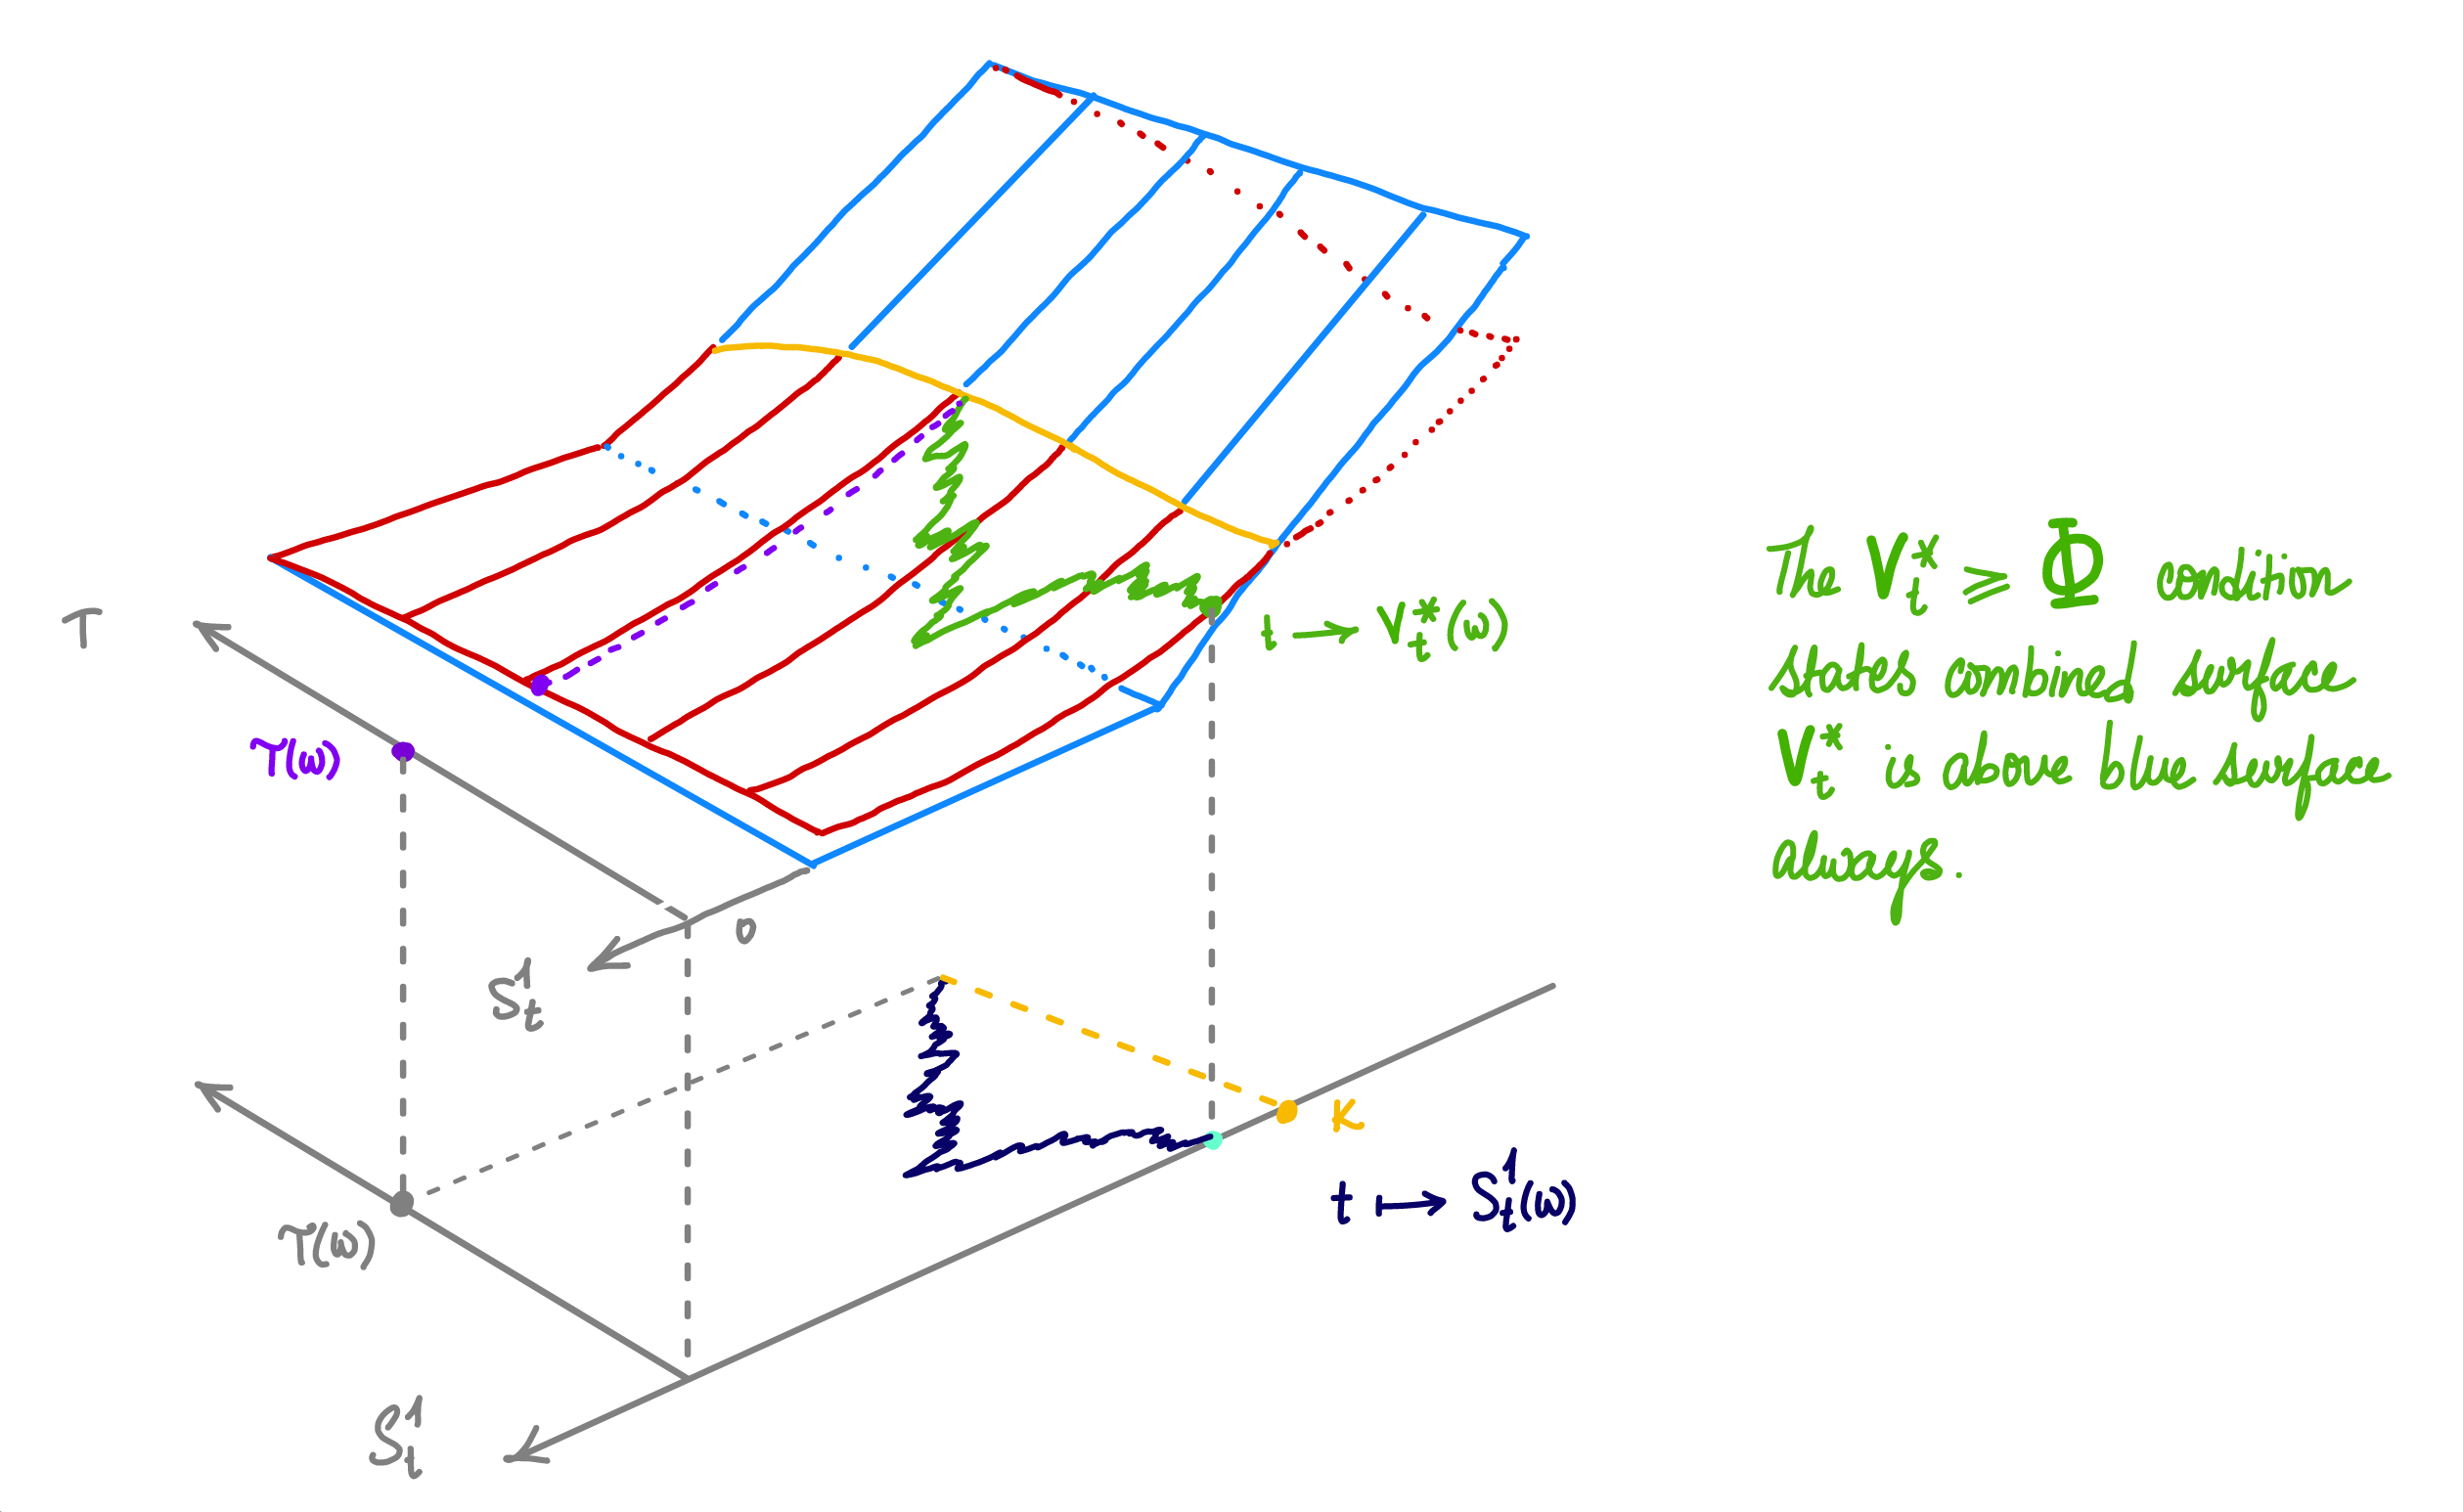

The $V^*$ notation is often used for the solution surface created by joining the two parts. The notation comes from the fact that in American Option pricing the solution surface is solved via evaluating a maximum over all possible exercise strategies. We will not get into Snell envelope etc yet (probably).

### Part 2: Continuous & Discrete LCP Formulation

Notice the remarkable structural symmetry between the two regions we just derived. At *every* point $(S, \tau)$, one of the two inequalities is binding (equal to zero) while the other is strictly positive. We can package the PDE, the obstacle constraint, and the unknown free boundary $S^*(\tau)$ into a single unified system without ever explicitly tracking $S^*(\tau)$!

#### 1. The Continuous Linear Complementarity Problem (LCP)
Define the Black-Scholes PDE residual operator:
$$\mathcal{F}(V) \equiv \frac{\partial V}{\partial \tau} - \mathcal{L}V = \frac{\partial V}{\partial \tau} - \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} - (r - q) S \frac{\partial V}{\partial S} + r V \quad {(\text{often used as } \mathcal{F}=\partial_{\tau} + \mathcal{L})}$$

Then the American option pricing problem is completely equivalent to the **LCP**:
$$\begin{cases}
\mathcal{F}(V) \ge 0 & \text{(Value decay inequality)} \\
V - \Phi \ge 0 & \text{(Constraint)} \\
\mathcal{F}(V) \cdot (V - \Phi) = 0 & \text{(Complementarity)}
\end{cases}$$

**Remark:** There is an alternate version we see. That has the first inequality inverted. That comes from never having changed the time $t$ to $\tau$. Also the structure of $\mathcal{F}$ is different because we use $\partial_{\tau} + \mathcal{L}_{BS}$ instead of $\partial_{\tau} + \mathcal{L}$. They differ only by a negative sign. 
$$- \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} - (r - q) S \frac{\partial V}{\partial S} + r V =: \mathcal{L}(V)
\neq \mathcal{L}_{\text{BS}} V :=  \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + (r - q) S \frac{\partial V}{\partial S} - r V$$

**Why this is brilliant for numerical methods:** Instead of solving a moving-boundary PDE where you have to guess $S^*(\tau)$ at every time step, you solve a fixed-domain algebraic complementarity problem. Once you have $\mathbf{V}$, the free boundary $S^*(\tau)$ simply pops out as the rightmost grid point where $V_i = \Phi_i$!

#### 2. Discretizing the LCP at Each Time Step
Recall from Topic 1 that our unconstrained $\theta$-scheme step from $\tau^n$ to $\tau^{n+1}$ is:
$$A\mathbf{V}^{n+1} = \mathbf{d}^n$$
where $A = I - \theta \Delta \tau L$ and $\mathbf{d}^n = (I + (1 - \theta)\Delta \tau L)\mathbf{V}^n + \Delta \tau (\theta \mathbf{b}^{n+1} + (1 - \theta)\mathbf{b}^n)$. Dividing through by $\Delta \tau$, the discrete analog of $\mathcal{F}(V) \ge 0$ is simply $A\mathbf{V}^{n+1} - \mathbf{d}^n \ge \mathbf{0}$ (applied component-wise). Let $\mathbf{\Phi}$ be the vector of discrete payoffs $\Phi_i = \max(K - S_i, 0)$ at the interior nodes $i = 1, \dots, N-1$.

At every time step $n \to n+1$, we must solve the **Discrete LCP**:
$$\begin{cases}
A\mathbf{V}^{n+1} - \mathbf{d}^n \ge \mathbf{0} \\
\mathbf{V}^{n+1} - \mathbf{\Phi} \ge \mathbf{0} \\
(A\mathbf{V}^{n+1} - \mathbf{d}^n)^T (\mathbf{V}^{n+1} - \mathbf{\Phi}) = 0
\end{cases}$$

*(Note: Because both vectors are component-wise non-negative, their inner product being zero forces $(A\mathbf{V}^{n+1} - \mathbf{d}^n)_i \cdot (V_i^{n+1} - \Phi_i) = 0$ for every single grid index $i$ individually!)*

**Remark:** Let us see why naive projection fails. We might be tempted to solve $A\tilde{\mathbf{V}}^{n+1} = \mathbf{d}^n$ (the European step) and then simply set $\mathbf{V}^{n+1} = \max(\tilde{\mathbf{V}}^{n+1}, \mathbf{\Phi})$. While that gives a rough approximation (explicit projection), it **violates the LCP** because clamping $V_i$ upward changes $(A\mathbf{V}^{n+1})_i$ at neighboring nodes $i-1$ and $i+1$, breaking smooth pasting and destroying $O(\Delta \tau^2)$ accuracy. To solve the true coupled LCP, we need **PSOR** or the **Penalty Method**.

## Topic 3: PSOR vs. Penalty Method

### Part 1: Projected Successive Over-Relaxation (PSOR)

PSOR is the classic iterative algorithm for solving the discrete LCP $A\mathbf{x} \ge \mathbf{d},\; \mathbf{x} \ge \mathbf{\Phi},\; (A\mathbf{x} - \mathbf{d})^T(\mathbf{x} - \mathbf{\Phi}) = 0$ (writing $\mathbf{x} = \mathbf{V}^{n+1}$ for brevity).

#### 1. How Gauss-Seidel & SOR Work for Linear Systems
For a tridiagonal matrix $A$ with lower diagonal $a_i$, main diagonal $b_i$, and upper diagonal $c_i$, the $i$-th row of $A\mathbf{x} = \mathbf{d}$ is:
$$a_i x_{i-1} + b_i x_i + c_i x_{i+1} = d_i$$

See the geometry behind **Gauss-Seidel** method at [**Numerical Analysis**](https://kalaapks.github.io/notesComp.html#table-NM) (in fact see [**handwritten**](https://kalaapks.github.io/pdf/Comp/Numerical%20Methods%20KS%20(H).pdf) one for the geometry, under "1.2. Solution of Linear Equation"). In Gauss-Seidel method, we sweep through $i = 1, \dots, N-1$ sequentially, updating $x_i$ using the newest available values ($x_{i-1}^{(k+1)}$ already updated in the current sweep, and $x_{i+1}^{(k)}$ cannot be updated and hence uses the value from the previous sweep):
$$(x_i^{k+1})_{\text{GS}} = \frac{1}{b_i}\left( d_i - a_i x_{i-1}^{(k+1)} - c_i x_{i+1}^{(k)} \right)$$

So essentially at $(k+1)^{th}$ iteration, the past variables are using updated value and future still is stuck at previous value (since that is the last available value). We have fixed the order of update $x_{i-1} \rightarrow x_i \rightarrow x_{i+1}$. Then Diagonal Dominance gives us what order do we hit the planes in $\mathbb{R}^3$ (literal planes here since three variables $(x_{i-1}, x_i, x_{i+1})$ are involved).

<!-- **Successive Over-Relaxation (SOR)** accelerates convergence by taking a weighted step with relaxation parameter $\omega \in (1, 2)$:
$$x_i^{\text{SOR}} = x_i^{(k)} + \omega \left( x_i^{\text{GS}} - x_i^{(k)} \right) = (1 - \omega)x_i^{(k)} + \frac{\omega}{b_i}\left( d_i - a_i x_{i-1}^{(k+1)} - c_i x_{i+1}^{(k)} \right)$$ -->

**Successive Over-Relaxation (SOR)** accelerates convergence by taking a weighted step from the old value $x_i^{(k)}$ past the new Gauss-Seidel target $(x_i^{k+1})_{\text{GS}}$ using a relaxation parameter $\omega \in (1, 2)$:$$(x_i^{k+1})_{\text{SOR}} = x_i^{(k)} + \omega \left( (x_i^{k+1})_{\text{GS}} - x_i^{(k)} \right) = (1 - \omega)x_i^{(k)} + \frac{\omega}{b_i}\left( d_i - a_i x_{i-1}^{(k+1)} - c_i x_{i+1}^{(k)} \right)$$

Notice what every superscript means in the $(k+1)^{\text{th}}$ sweep:
- $x_i^{(k)}$: where node $i$ was at the end of the previous sweep $k$ (our starting point).
- $(x_i^{k+1})_{\text{GS}}$: the pure Gauss-Seidel point on the $i$-th hyperplane (computed using the already-updated left neighbor $x_{i-1}^{(k+1)}$ and the still-unupdated right neighbor $x_{i+1}^{(k)}$).
- $(x_i^{k+1})_{\text{SOR}}$: our actual updated value for sweep $k+1$, obtained by taking the Gauss-Seidel correction vector $\Delta x_i = (x_i^{k+1})_{\text{GS}} - x_i^{(k)}$ and scaling it by $\omega > 1$.

Since we have seen already picture of Gauss-Seidel in 3D as orthogonal projections jumping from plane to plane in a fixed cycle ($x_1 \to x_2 \to x_3$), SOR is easiest to understand directly on top of that exact picture. When the three planes intersect at a very shallow angle (which happens in PDEs because neighboring grid points $x_{i-1}, x_i, x_{i+1}$ are tightly coupled), moving orthogonally from Plane 1 $\to$ Plane 2 $\to$ Plane 3 produces a tiny, zig-zagging staircase inside a narrow wedge. Every sweep moves you in the right general direction toward $\mathbf{x^*}$, but each step is very short and that is because we are stopping the exact moment we hit the current plane.

$\omega \in (1, 2)$ (Over-Relaxation): SOR says us to walk along the $x_i$-axis from $x_i^{(k)}$, hit Plane $i$ at $(x_i^{k+1})_{\text{GS}}$, and keep walking straight through the plane by an extra fraction $(\omega - 1)$ of your step! Let us first see why this makes sense for two lines cutting at a shallow angle, then we can imagine for planes too. Note that under relaxation, we reached around the same point we reached under usual Gauss-Seidal but in half the steps.

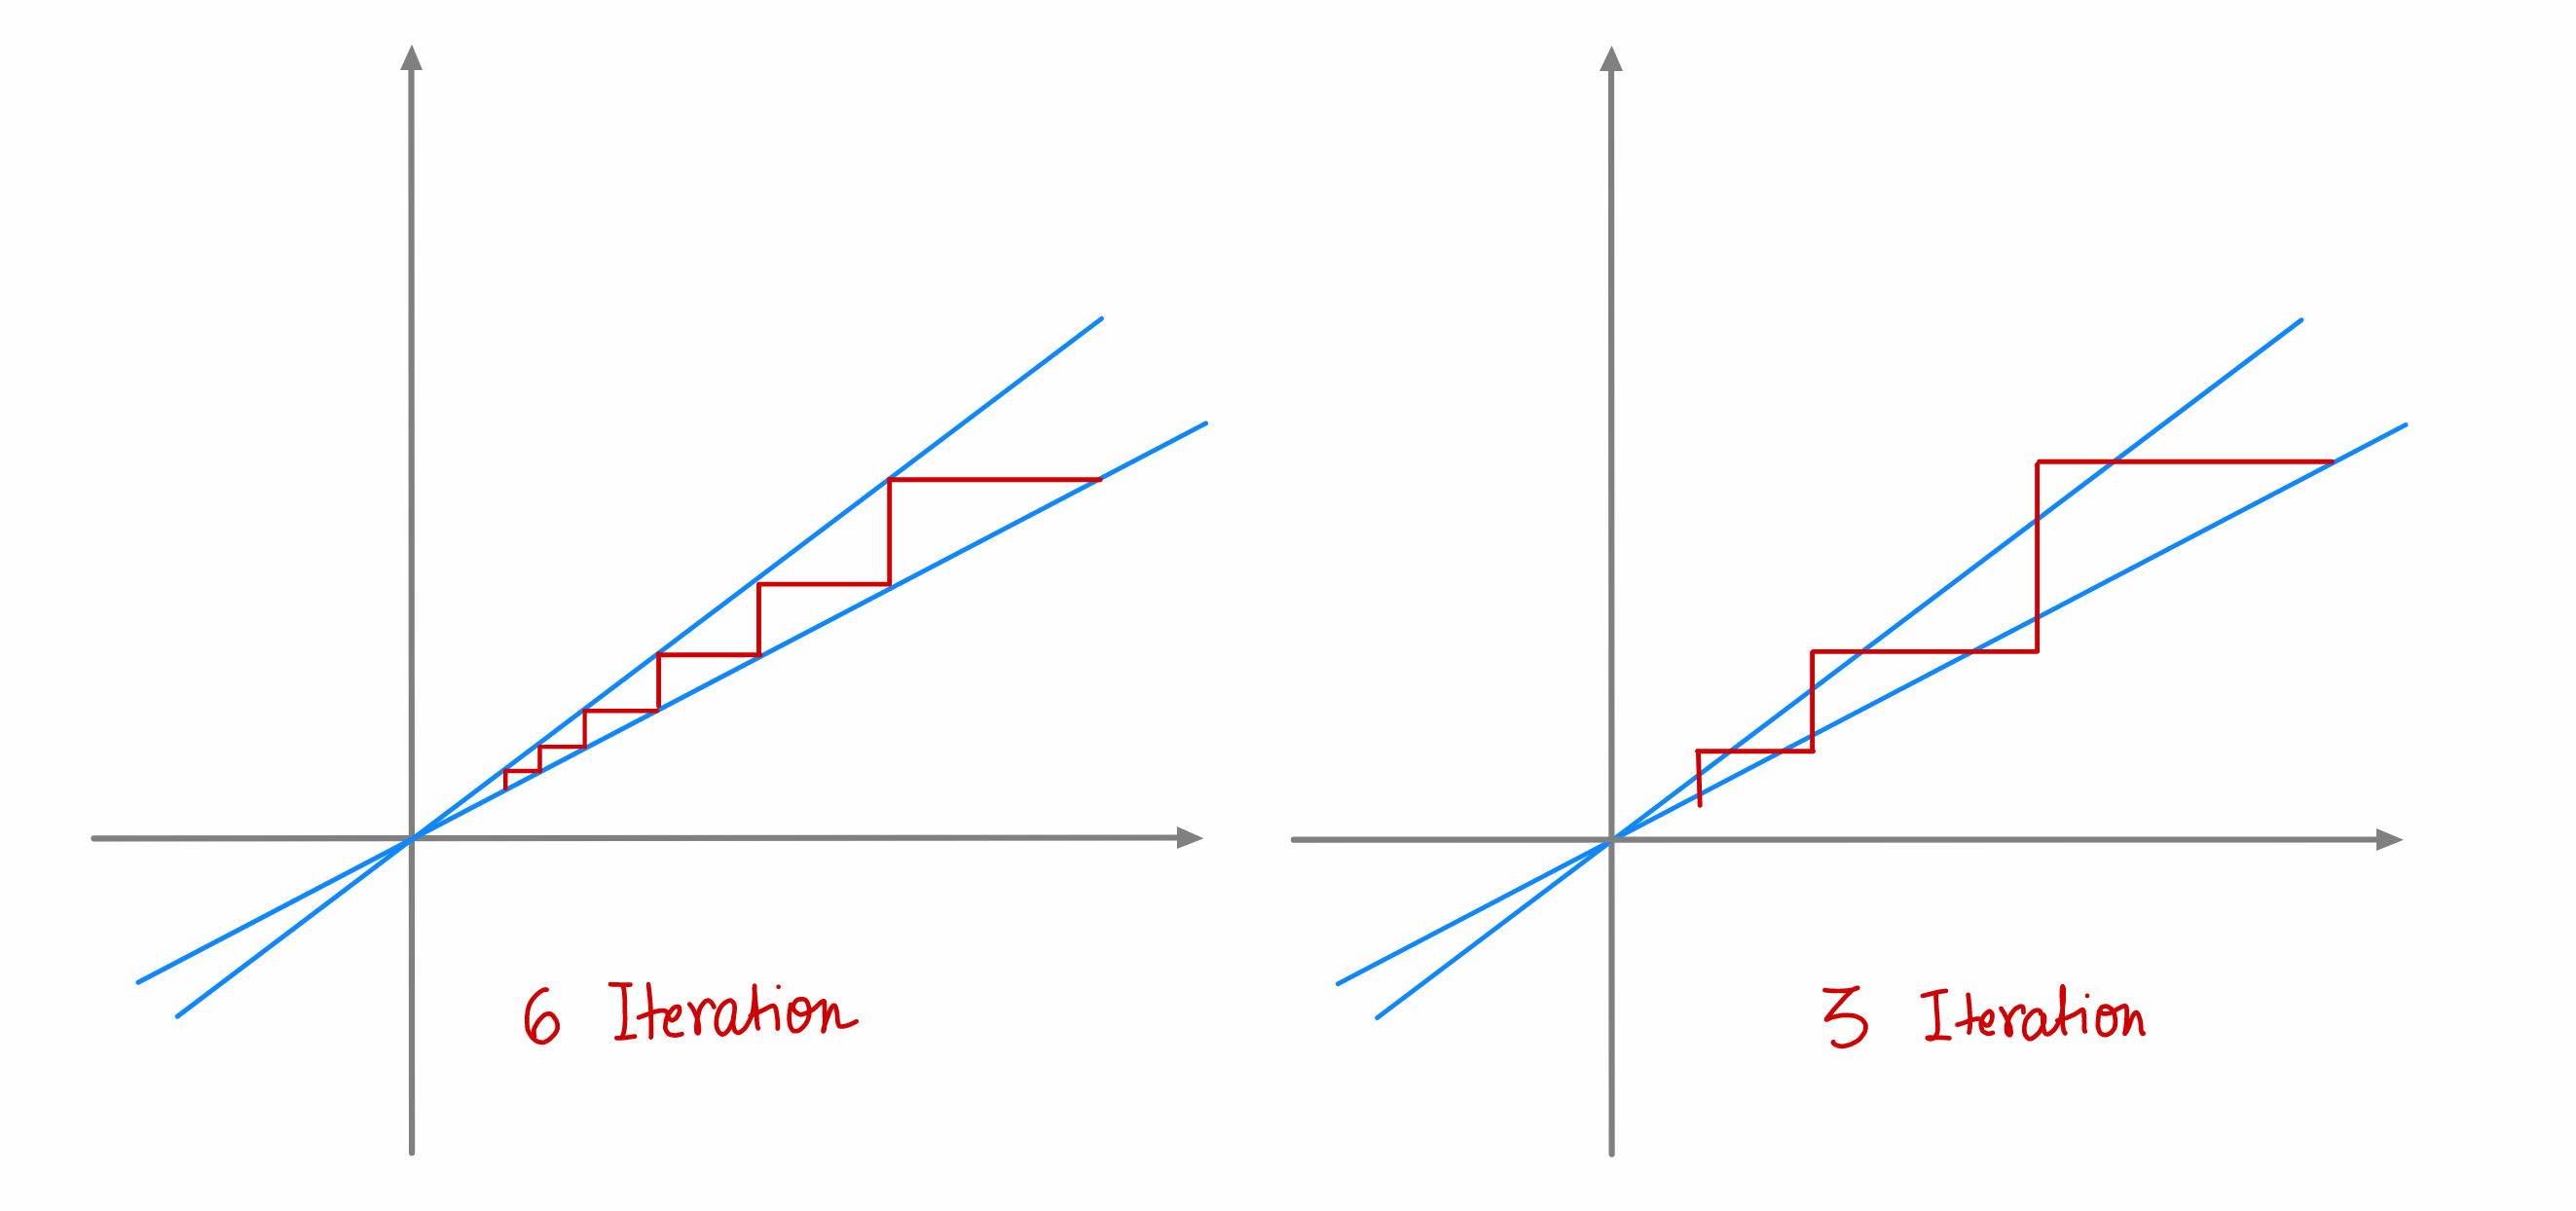

The upper bound 2 on $\omega$ is due to other mathematical reasons (which I haven't explored yet) but geometrically it makes sense that there will be a upper limit since if we go too far, we will probably miss the intersection due to overshooting.